In [ ]:
#let's goooo

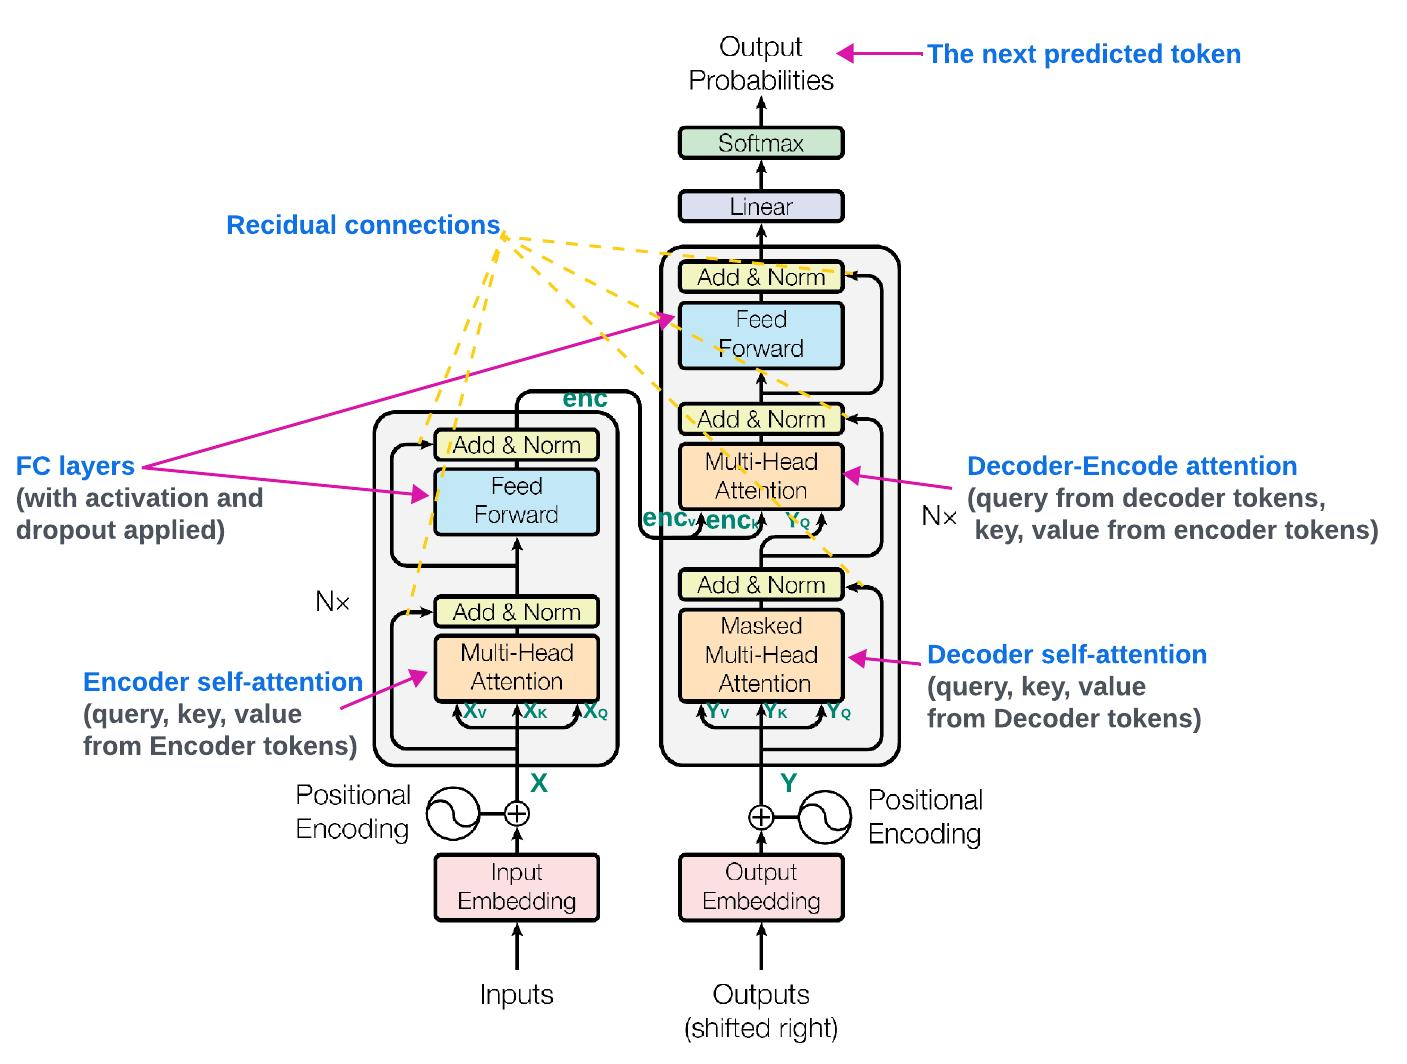

In [9]:
import torch
import torch.nn as nn

vocab_size=10000
embedding_dim=128

embedding=nn.Embedding(vocab_size,embedding_dim)

#three tokens
input_ids=torch.tensor([101,205,309])

output=embedding(input_ids)

# it will show 2->(3 x 128)
print(output.ndim)
# print shape
print(output.shape)

print(output)

2
torch.Size([3, 128])
tensor([[ 3.0637e-02, -5.8336e-01,  7.7226e-01, -5.4626e-02,  7.1671e-01,
         -1.2491e+00, -4.2873e-01,  1.3454e+00, -3.7084e-02, -7.7740e-04,
         -5.3599e-01, -1.0834e+00,  1.3766e+00, -1.4442e+00, -1.3549e+00,
          2.3454e+00,  4.9709e-02, -2.5792e-01,  3.3896e-01, -8.3613e-01,
          2.9424e-02,  1.4113e+00,  1.3320e+00, -1.4883e+00, -1.5555e-01,
         -2.8115e-01,  4.6188e-01,  1.2290e+00, -2.8773e+00,  1.1681e-01,
         -1.6630e+00, -8.6777e-01,  3.9296e-01, -4.3855e-01, -7.5761e-01,
         -1.2045e+00,  3.4977e-01,  2.0241e+00,  1.5417e-01,  1.1185e+00,
         -1.8558e-02,  9.0452e-01, -6.3376e-01,  5.7744e-01, -7.1984e-01,
          5.7339e-01,  3.1449e-01, -1.8538e-01,  1.0554e-01,  8.6999e-02,
          2.0740e+00,  5.6632e-01,  6.5489e-01, -9.1569e-01, -1.1810e+00,
          4.1222e-01,  1.6890e-01, -4.5105e-01, -4.9277e-01,  6.5874e-01,
         -1.1059e+00,  1.3787e+00,  4.5459e-01, -7.7281e-01,  8.2290e-01,
          7.066

In [12]:
#Positional embeddings

# Dog bites man
# Man bites dog

import torch.nn as nn
max_seq_len=100
embedding_dim=128

position_embedding = nn.Embedding(
    max_seq_len,
    embedding_dim
)

positions=torch.arange(5)
pos_vectors=position_embedding(positions)
print(pos_vectors.shape)

torch.Size([5, 128])


For each token we have to combine (token embedding and posisitonal embedding)

In [13]:
import torch
import torch.nn as nn

vocab_size = 10000
max_seq_len = 100
embedding_dim = 128


token_embedding = nn.Embedding(
    vocab_size,
    embedding_dim
)

position_embedding = nn.Embedding(
    max_seq_len,
    embedding_dim
)

input_ids = torch.tensor([[101, 205, 309, 410]])

positions=torch.arange(input_ids.shape[1])
token_vectors = token_embedding(input_ids)
position_vectors = position_embedding(positions)

x = token_vectors + position_vectors

print("Token embeddings:", token_vectors.shape)
print("Position embeddings:", position_vectors.shape)
print("Combined:", x.shape)


Token embeddings: torch.Size([1, 4, 128])
Position embeddings: torch.Size([4, 128])
Combined: torch.Size([1, 4, 128])


In [14]:
#to add attention layer -i will now reinvent it
# I will use pre-built library anywaays

In [15]:
pip install torch transformers

In [21]:
import torch
from  transformers import AutoTokenizer, AutoModelForCausalLM

model_name="distilgpt2"

#we are loading pretrained tokenszer and model from disitlgp2
tokenizer=AutoTokenizer.from_pretrained(model_name)
model=model = AutoModelForCausalLM.from_pretrained(model_name)

prompt = "Once upon a time in a quiet village,"
#print(model.config)
inputs = tokenizer(prompt, return_tensors="pt")
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.7
    )

response = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print(response)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Once upon a time in a quiet village, a boy's home is engulfed in flames. A forest is burned and a man's house is burned, and a woman's house is burned, and a man's house is burned, and a man's house is burned, and a man's house


In [22]:
print(model.config.n_layer)
print(model.config.n_head)
print(model.config.n_embd)
print(model.config.vocab_size)

6
12
768
50257
